In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from pathlib import Path
import math
from scipy.interpolate import CubicSpline 

import tools
import my_plot as mplt

In [2]:
def extract_PSEE(folder_path):
    """Extract scattering basis transfer function data from files in a folder """
    folder = Path(folder_path) / "FH" / "yn_T_aniso_system" 
    
    file_path = next(folder.glob("power_spectra_ymax15_lmax15_adiabatic.dat.dat"))

    ell = []
    EE = []
    muE = []
    yE = []

    ell = np.loadtxt(file_path, comments='#')[:, 0]
    EE = np.loadtxt(file_path, comments='#')[:, 6]
    muE = np.loadtxt(file_path, comments='#')[:, 8]
    yE = np.loadtxt(file_path, comments='#')[:, 9]

    return np.array(ell), np.array(EE), np.array(yE), np.array(muE)

In [3]:
ell , EE, yE, muE = extract_PSEE("../Data/Dark-photons/output_dp_PS/outputs-dp1.0_PS/")
_ , EE_1, yE_1, muE_1 = extract_PSEE("../Data/Dark-photons/output_dp_PS/outputs-dp1.1_PS/")
_ , EE_2, yE_2, muE_2 = extract_PSEE("../Data/Dark-photons/output_dp_PS/outputs-dp1.2_PS/")
_ , EE_3, yE_3, muE_3 = extract_PSEE("../Data/Dark-photons/output_dp_PS/outputs-dp1.3_PS/")



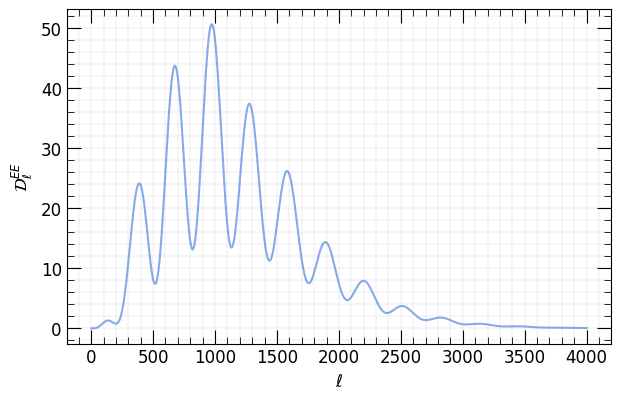

In [8]:
colors = mplt.set_colors(4, palette="dark_photons")
fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))

ax.plot(ell, EE, color=colors[0], alpha=0.7, linestyle="-", label="EE")


mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=False, y_label="$\\mathcal{D}_\\ell^{{EE}}$", y_log=False, title=None)


#ax.legend()
plt.show()


The following two plots are for me only, we are not including the first line in the paper. But they nicely show how very early energy injections thermalise immediatly, what we see it is basically only a very small signal due to numerical noise probably

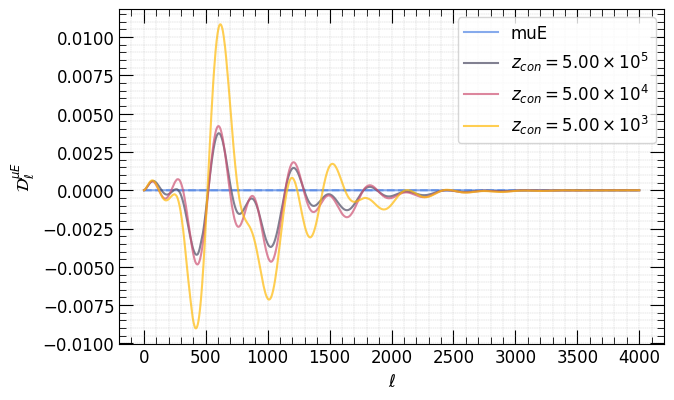

In [15]:
colors = mplt.set_colors(4, palette="dark_photons")
fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))

ax.plot(ell, muE, color=colors[0], alpha=0.7, linestyle="-", label="muE")
ax.plot(ell, -muE, color=colors[0], alpha=0.7, linestyle="--")

ax.plot(ell, muE_1, color=colors[1], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e5)}")
ax.plot(ell, muE_2, color=colors[2], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e4)}")
ax.plot(ell, muE_3, color=colors[3], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e3)}")

mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=False, y_label="$\\mathcal{D}_{\\ell}^{{\\mu E}}$", y_log=False, title=None)


ax.legend()
plt.show()

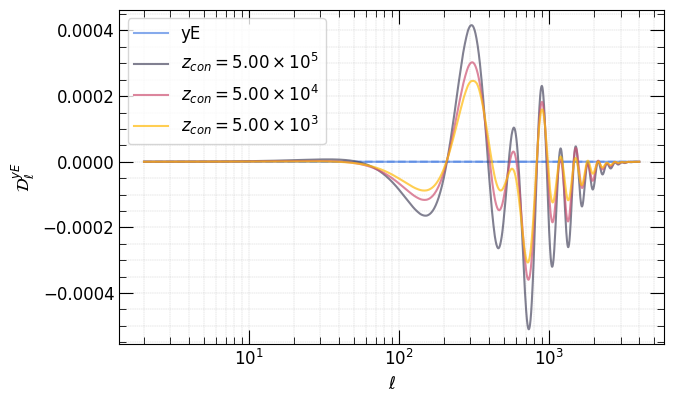

In [17]:
colors = mplt.set_colors(4, palette="dark_photons")
fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))

ax.plot(ell, yE, color=colors[0], alpha=0.7, linestyle="-", label="yE")
ax.plot(ell, -yE, color=colors[0], alpha=0.7, linestyle="--")


ax.plot(ell, yE_1, color=colors[1], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e5)}")
ax.plot(ell, yE_2, color=colors[2], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e4)}")
ax.plot(ell, yE_3, color=colors[3], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e3)}")


mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=True, y_label="$\\mathcal{D}_{\\ell}^{{y E}}$", y_log=False, title=None)


ax.legend()
plt.show()

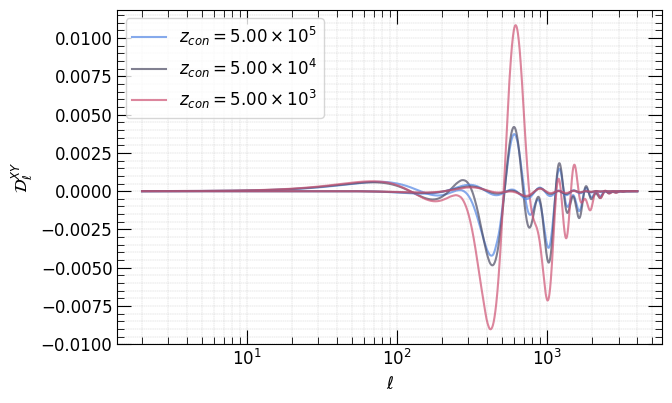

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))



ax.plot(ell, muE_1, color=colors[1], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e5)}")
ax.plot(ell, muE_2, color=colors[2], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e4)}")
ax.plot(ell, muE_3, color=colors[3], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e3)}")

ax.plot(ell, yE_1, color=colors[1], alpha=0.7, linestyle="-")
ax.plot(ell, yE_2, color=colors[2], alpha=0.7, linestyle="-")
ax.plot(ell, yE_3, color=colors[3], alpha=0.7, linestyle="-")


mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=True, y_label="$\\mathcal{D}_{\\ell}^{{XY}} $", y_log=False, title=None)

# ax.annotate("$yE$", xy=(5, 3e-4), fontsize=12)
# ax.annotate("$\\mu E$", xy=(5, 2e-2), fontsize=12)


ax.legend()
plt.show()